In [30]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 3 - Session 3
# XGBoost and Model Comparison
# ==========================================

# Import libaries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib 
from matplotlib import Path 
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

In [31]:
# Load dataset
df = pd.read_csv("../data/processed/ml_features.csv")

# Convert Dat column 
df["Date"] = pd.to_datetime(df["Date"])

# Sort chronologically 
df = df.sort_values("Date").reset_index(drop=True)
print(df.head())
print("Dataset shape:",df.shape)
print(df.info())

# Define target
target = "GBPUSD_Target_Volatility_5D"

# Remove all target variables from features
target_columns = ["GBPUSD_Target_Volatility_5D","EURUSD_Target_Volatility_5D","USDJPY_Target_Volatility_5D"]

# Create feature dataset
X = df.drop(columns=["Date"] + target_columns, errors="ignore")

# Create target dataset
y = df[target]

# Remove observations where target is missing
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()
dates = df.loc[valid_rows, "Date"].copy()

# Remove any remaining missing feature observations
valid_features = X.notna().all(axis=1)
X = X.loc[valid_features]
y = y.loc[valid_features]
dates = dates.loc[valid_features]
print("Features:", X.shape)
print("Target:", y.shape)
print("Number of features:", X.shape[1])

        Date  GBPUSD_Return_1D  GBPUSD_Return_5D  GBPUSD_Volatility_5D  \
0 2022-01-26          0.001594         -0.006580              0.002668   
1 2022-01-27         -0.003165         -0.010330              0.002516   
2 2022-01-28         -0.005918         -0.015396              0.002883   
3 2022-01-31          0.001126         -0.011246              0.003447   
4 2022-02-01          0.003133         -0.003254              0.003761   

   GBPUSD_Volatility_20D  GBPUSD_Volatility_60D  GBPUSD_Momentum_5D  \
0               0.003079               0.003862           -0.006580   
1               0.002972               0.003805           -0.010330   
2               0.003243               0.003462           -0.015396   
3               0.003223               0.003463           -0.011246   
4               0.003263               0.003413           -0.003254   

   GBPUSD_Momentum_20D  EURUSD_Return_1D  EURUSD_Return_5D  ...  \
0             0.005769         -0.001730         -0.002216  .

In [32]:
# Calculate split points
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Five observation gap to reduce target overlap
gap = 5

# Training dataset
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation dataset
X_val = X.iloc[train_end + gap:val_end]
y_val = y.iloc[train_end + gap:val_end]

# Testing dataset
X_test = X.iloc[val_end + gap:]
y_test = y.iloc[val_end + gap:]

# Corresponding dates
test_dates = dates.iloc[val_end + gap:]
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

Training observations: 864
Validation observations: 180
Testing observations: 181


In [33]:
# Initialise XGBoost model
xgb_model = XGBRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)
print("XGBoost model initialised successfully.")

XGBoost model initialised successfully.


In [34]:
# Train XGBoost model
xgb_model.fit(X_train,y_train,eval_set=[(X_val,y_val)],verbose=False)
print("XGBoost training completed.")

XGBoost training completed.


In [35]:
# Generate XGBoost predictions
xgb_predictions = xgb_model.predict(X_test)

# Create prediction dataframe
xgb_results = pd.DataFrame({"Date": test_dates.values, "Actual_Volatility": y_test.values, "XGBoost_Predicted": xgb_predictions})
print(xgb_results.head())

        Date  Actual_Volatility  XGBoost_Predicted
0 2026-02-17           0.004221           0.004477
1 2026-02-18           0.003979           0.004499
2 2026-02-19           0.003821           0.003476
3 2026-02-20           0.004448           0.003432
4 2026-02-23           0.004287           0.003736


In [36]:
# Calculate evaluation metrics
xgb_mae = mean_absolute_error(y_test,xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test,xgb_predictions))
xgb_r2 = r2_score(y_test,xgb_predictions)

# Display results 
print("\nXGBoost Model Performance")
print(f"MAE: {xgb_mae:.6f}")
print(f"RMSE: {xgb_rmse:.6f}")
print(f"R2: {xgb_r2:.6f}")


XGBoost Model Performance
MAE: 0.001620
RMSE: 0.001929
R2: -0.451846


In [37]:
# Initialise Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train Random Forest
rf_model.fit(X_train, y_train)

# Generate predictions 
rf_predictions = rf_model.predict(X_test)
print("Random Forest training completed.")

Random Forest training completed.


In [38]:
# Random forest metrics
rf_mae = mean_absolute_error(y_test,rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test,rf_predictions))
rf_r2 = r2_score(y_test,rf_predictions)

# Display results 
print("\nRandom Forest Performance")
print(f"MAE: {rf_mae:.6f}")
print(f"RMSE: {rf_rmse:.6f}")
print(f"R2: {rf_r2:.6f}")


Random Forest Performance
MAE: 0.001801
RMSE: 0.002072
R2: -0.675897


In [39]:
# Create model comparison dataframe
comparison = pd.DataFrame({"Model": ["Random Forest","XGBoost"],"MAE": [rf_mae, xgb_mae],"RMSE": [rf_rmse,xgb_rmse],"R2": [rf_r2,xgb_r2]})
print("\nModel Performance Comparison")
print(comparison.to_string(index=False))


Model Performance Comparison
        Model      MAE     RMSE        R2
Random Forest 0.001801 0.002072 -0.675897
      XGBoost 0.001620 0.001929 -0.451846


In [40]:
from arch import arch_model
import numpy as np
import pandas as pd

# Extract GBP/USD daily returns
returns_decimal = df.loc[
    valid_rows, "GBPUSD_Return_1D"
].copy()
returns_decimal = returns_decimal.loc[valid_features]

# Store GARCH predictions
garch_predictions = []

# Rolling expanding-window forecasts
for position in test_positions:

    # Historical returns available at prediction date
    historical_returns = returns_decimal.iloc[
        :position + 1
    ]

    # Fit GARCH(1,1)
    model = arch_model(

        historical_returns,

        mean="Zero",

        vol="GARCH",

        p=1,

        q=1,

        dist="t",

        rescale=False

    )

    fitted_model = model.fit(disp="off")

    # Forecast next five trading days
    forecast = fitted_model.forecast(

        horizon=5,

        reindex=False

    )

    # Extract daily forecast variances
    forecast_variance = forecast.variance.iloc[-1].values

    # Calculate average five-day daily volatility
    five_day_volatility = np.sqrt(
        np.mean(forecast_variance)
    )

    garch_predictions.append(five_day_volatility)

garch_predictions = np.array(garch_predictions)
print("GARCH forecasting completed.")
print("Average GARCH volatility:",
      np.mean(garch_predictions))

GARCH forecasting completed.
Average GARCH volatility: 0.004513310551991626


In [41]:
# Calculate GARCH metrics
garch_mae = mean_absolute_error(
    y_test,
    garch_predictions
)
garch_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        garch_predictions
    )
)
garch_r2 = r2_score(
    y_test,
    garch_predictions
)
print("\nGARCH performance:")
print(f"MAE:  {garch_mae:.6f}")
print(f"RMSE: {garch_rmse:.6f}")
print(f"R2:   {garch_r2:.6f}")


GARCH performance:
MAE:  0.001430
RMSE: 0.001708
R2:   -0.138793


In [42]:
# Create final comparison
final_comparison = pd.DataFrame({"Model": ["GARCH(1,1)","Random Forest","XGBoost"],"MAE": [garch_mae,rf_mae,xgb_mae], "RMSE": [garch_rmse,rf_rmse,xgb_rmse], "R2": [garch_r2,rf_r2,xgb_r2]})

# Sort by MAE
final_comparison = final_comparison.sort_values(by="MAE").reset_index(drop=True)
print("\nFinal model comparison")
print(final_comparison.to_string(index=False))

# Identify best performing model by MAE
best_model = final_comparison.iloc[0]["Model"]
print("\nBest performing model based on MAE:", best_model)


Final model comparison
        Model      MAE     RMSE        R2
   GARCH(1,1) 0.001430 0.001708 -0.138793
      XGBoost 0.001620 0.001929 -0.451846
Random Forest 0.001801 0.002072 -0.675897

Best performing model based on MAE: GARCH(1,1)


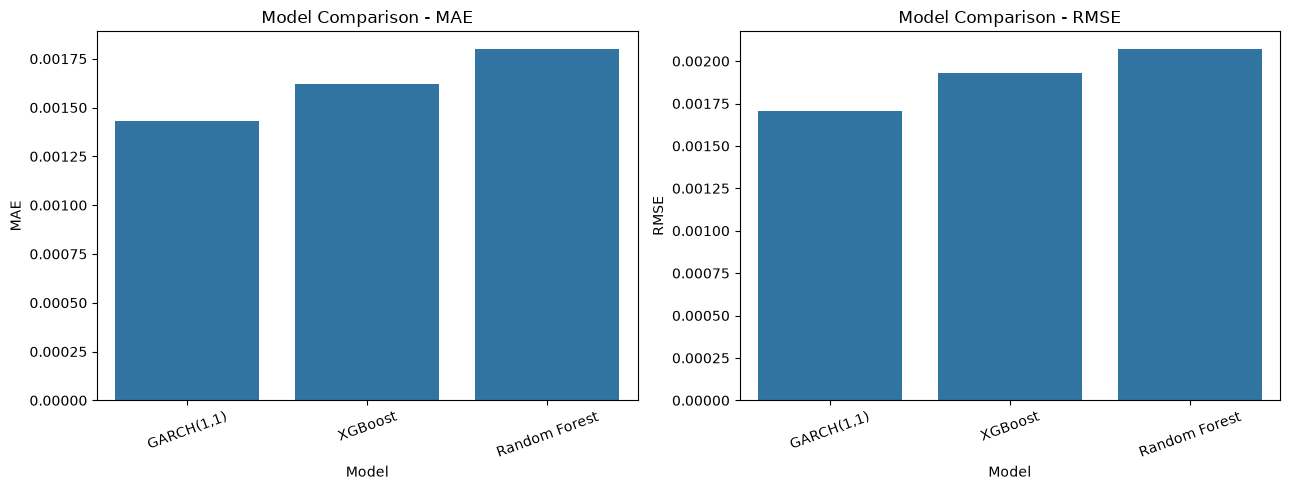

<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot MAE and RMSE 
import os

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=final_comparison, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Model Comparison - MAE")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=final_comparison, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Model Comparison - RMSE")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

from pathlib import Path

# Set project root (one level above notebooks)
PROJECT_ROOT = Path.cwd().parent

# Create output directory in project root
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "xgboost"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save chart
plt.savefig(OUTPUT_DIR / "model_comparisons.png", dpi=300)
plt.show()

In [50]:
# Extract feature importance
importance = pd.DataFrame({"Feature": X_train.columns, "Importance": xgb_model.feature_importances_})

# Sort by importance
importance = importance.sort_values(by="Importance",ascending=False)
print("\nXGBoost feature importance")
print(importance.to_string(index=False))


XGBoost feature importance
              Feature  Importance
GBPUSD_Volatility_20D    0.168101
   GBPUSD_Momentum_5D    0.099589
GBPUSD_Volatility_60D    0.082600
     GBPUSD_Return_5D    0.076748
EURUSD_Volatility_60D    0.066629
  GBPUSD_Momentum_20D    0.049662
EURUSD_Volatility_20D    0.045486
USDJPY_Volatility_20D    0.043535
  USDJPY_Momentum_20D    0.043339
 GBPUSD_Volatility_5D    0.033483
USDJPY_Volatility_60D    0.033022
   EURUSD_Momentum_5D    0.031284
 USDJPY_Volatility_5D    0.030986
     EURUSD_Return_5D    0.029677
  EURUSD_Momentum_20D    0.029298
     USDJPY_Return_5D    0.026637
   USDJPY_Momentum_5D    0.026374
     USDJPY_Return_1D    0.022429
     EURUSD_Return_1D    0.021486
 EURUSD_Volatility_5D    0.020636
     GBPUSD_Return_1D    0.018997


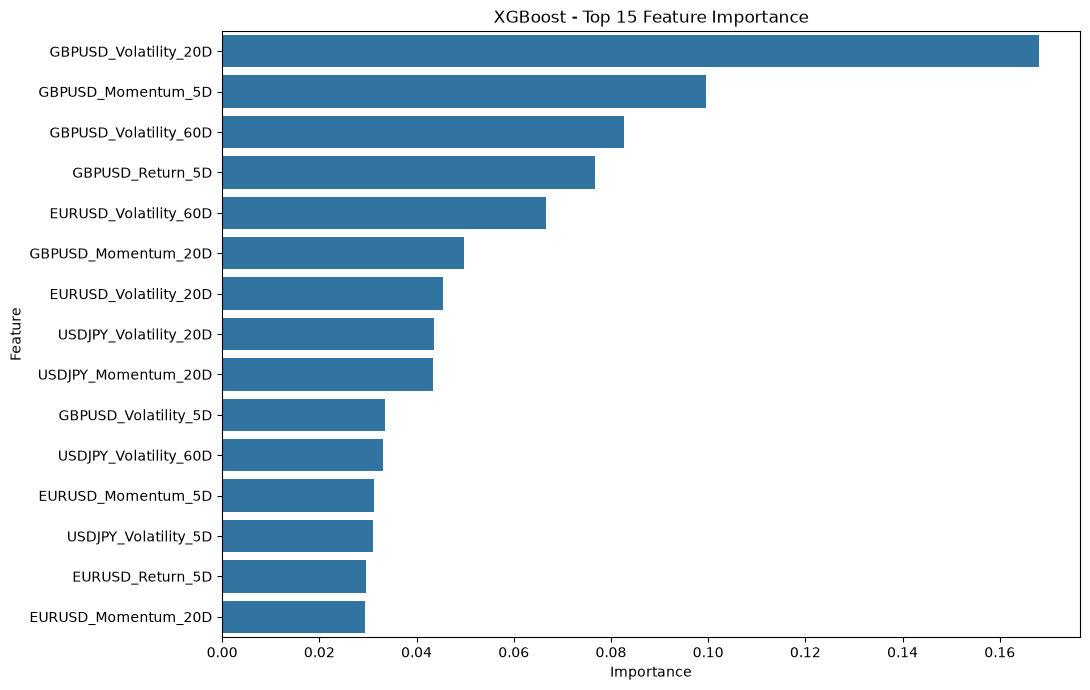

In [52]:
# Visualise feature importance
from pathlib import Path

# Set project root
PROJECT_ROOT = Path.cwd().parent

# Create XGBoost output directory
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "xgboost"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Plot feature importance
plt.figure(figsize=(11, 7))
sns.barplot(data=importance.head(15),x="Importance",y="Feature")
plt.title("XGBoost - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

# Save chart
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=300)
plt.show()

In [53]:
from pathlib import Path

# Create project root
PROJECT_ROOT = Path.cwd().parent

# Create output directories
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "xgboost"
MODEL_DIR = PROJECT_ROOT / "models" / "xgboost"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save XGBoost model
joblib.dump(xgb_model,MODEL_DIR / "xgboost_model.pkl")

# Save prediction results
xgb_results["Random_Forest_Predicted"] = rf_predictions
xgb_results["GARCH_Predicted"] = garch_predictions
xgb_results.to_csv(OUTPUT_DIR / "predictions.csv",index=False)


# Save model comparison
final_comparison.to_csv(OUTPUT_DIR / "model_comparison.csv",index=False)

# Save feature importance
importance.to_csv(OUTPUT_DIR / "feature_importance.csv",index=False)
print("All models and results saved successfully.")

All models and results saved successfully.
